<a href="https://colab.research.google.com/github/sahilkadam3095-ops/Transformer/blob/main/microGrad_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import libraries
import numpy as np
import math
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
#Make one function
def f(x):
   return 3*x**2 -4*x + 5



In [ ]:
# give paramter for function
f(3)

20

In [ ]:
# array of numbers declaration
s =np.arange(-5 , 5 , 0.25)
s

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

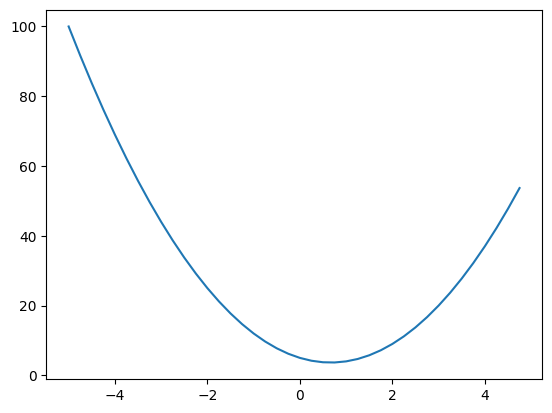

In [ ]:
# two elements and graph for relation between two elements
s =np.arange(-5 , 5 , 0.25)
v=f(s)
plt.plot(s,v)

In [ ]:
# steps to find slope
h=000.1
x=3.0
f(x)

20.0

In [ ]:
h=000.1
x=3.0
f(x+h)

21.430000000000007

In [ ]:
h=000.1
x=3.0
f(x+h)-f(x)

1.4300000000000068

In [ ]:
# error in prediction or slope
h=000.1
x=3.0
(f(x+h)-f(x))/h


14.300000000000068

In [ ]:
# negative parameter
h=000.1
x=-3.0
(f(x+h)-f(x))/h


-21.700000000000017

In [ ]:
# negative parameter
h=000.1
x=2/3
(f(x+h)-f(x))/h

0.29999999999999805

In [ ]:
# get go more complex

a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [ ]:
h=0000.1
# inputs
a=2.0
b=-3.0
c=10.0
d1=a*b+c
a+=h
d2=a*b +c
print("d1 :",d1)
print("d2 :",d2)
print("slope :",(d2-d1)/h)


d1 : 4.0
d2 : 3.6999999999999993
slope : -3.000000000000007


In [ ]:
h=0000.1
# inputs
a=2.0
b=-3.0
c=10.0
d1=a*b+c
b+=h
d2=a*b +c
print("d1 :",d1)
print("d2 :",d2)
print("slope :",(d2-d1)/h)

d1 : 4.0
d2 : 4.2
slope : 2.0000000000000018


In [ ]:
h=0000.1
# inputs
a=2.0
b=-3.0
c=10.0
d1=a*b+c
c+=h
d2=a*b +c
print("d1 :",d1)
print("d2 :",d2)
print("slope :",(d2-d1)/h)

d1 : 4.0
d2 : 4.1
slope : 0.9999999999999964


In [49]:

class Value:
    def __init__(self, data, _children=(), _op="",label=''):
        self.data = data
        self.grad = 0
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.grad = 0.0
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return Value(
            self.data + other.data,
            (self, other),
            "+"
        )

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return Value(
            self.data * other.data,
            (self, other),
            "*"
        )
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)

        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
            out._backward = _backward
            return out



        a=Value(2.0,label='a')
        b=Value(-3.0,label='b')
        c=Value(10.0,label='c')
        e=a*b;e.label='e'
        d=e+c;d.label='d'
        d._prev
        d._op


In [ ]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)

a.label = "a"
b.label = "b"
c.label = "c"

d = a * b + c
d.label = "d"

print(d)
print(type(d))


Value(data=4.0)
<class '__main__.Value'>


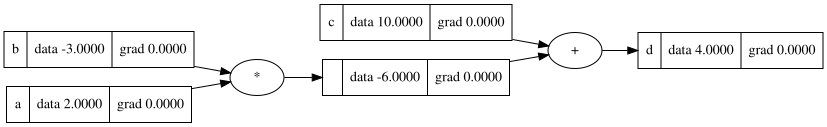

In [ ]:
from graphviz import Digraph

draw_dot(d)

In [ ]:
def lol():

  h=000.1
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L1=L.data



  a = Value(2.0+h, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L2=L.data

  print((L2 - L1)/h)

lol()

6.000000000000014


In [ ]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad


e = a * b
d = e + c

print(d.data)

4.0


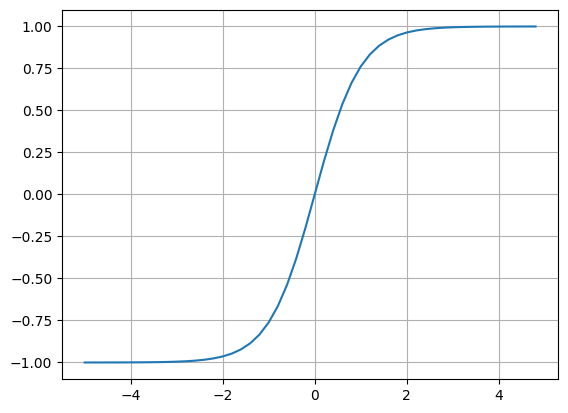

In [ ]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [ ]:
o.grad = 1.0

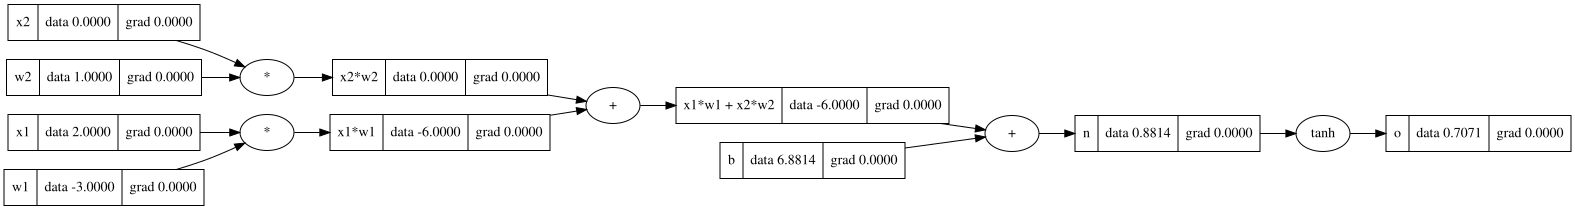

In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
draw_dot(o)

In [ ]:
o.data

0.7071067811865476

In [ ]:
o.grad = 1.0

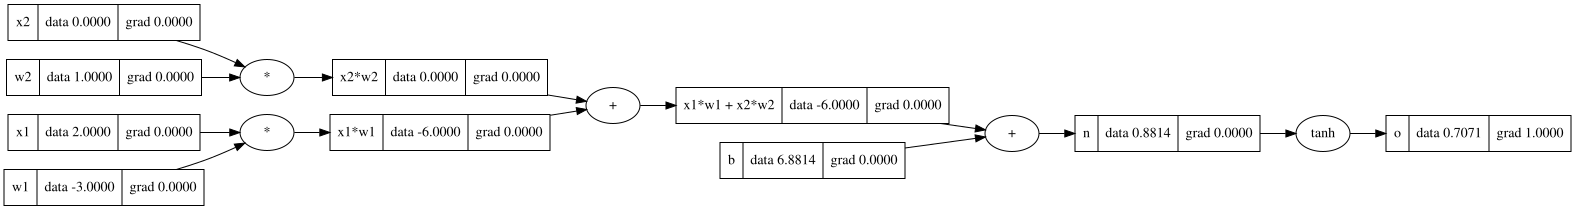

In [ ]:
draw_dot(o)

In [ ]:
1-o.grad**2

0.0

In [ ]:
n.grad =0.5

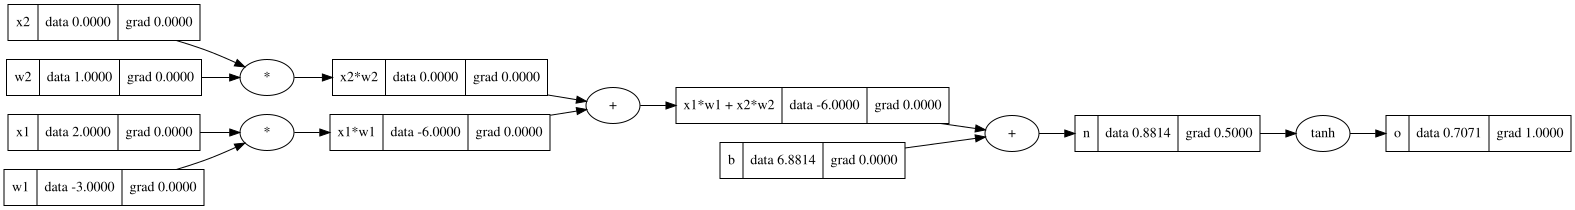

In [ ]:
draw_dot(o)

In [ ]:
x1w1x2w2.grad = 0.5
b.grad =0.5

In [ ]:
x1w1.grad =0.5

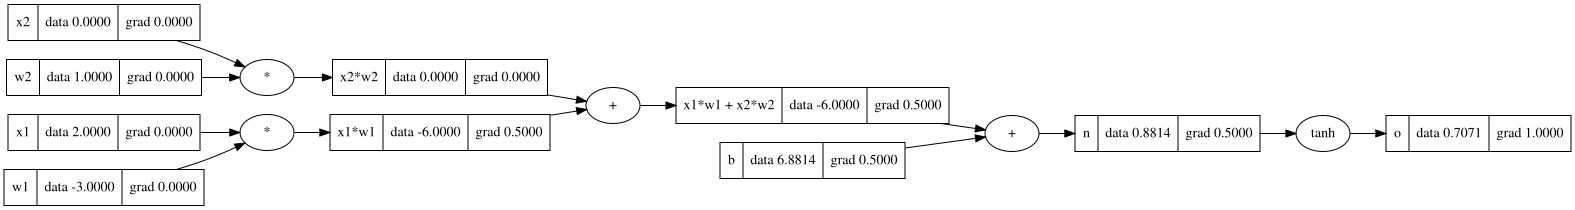

In [ ]:
draw_dot(o)

In [47]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [48]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad